# Part 1.1 – EDA
Overview of structure, distributions and missing data in the Movies dataset.

**Goal:** understand the structure and quality of the data so we know how to clean it before inserting it into MongoDB (Part 1.2), and which fields need care for the Part 2 queries (revenue, vote_average, runtime per decade/genre, cast gender, collections, ratings per user).

In [1]:
# Imports and path to the dataset folder
import ast
import pandas as pd
import matplotlib.pyplot as plt

DATA = "dataset/"

# Parse a Python-literal string (e.g. "[{'id': 16, 'name': 'Animation'}]") into a list/dict; None if missing or invalid
def parse(text):
    try:
        return ast.literal_eval(text) if isinstance(text, str) else None
    except (ValueError, SyntaxError):
        return None

## movies_metadata.csv

In [2]:
# Load movie metadata and show its size and column types
movies = pd.read_csv(DATA + "movies_metadata.csv", low_memory=False)
print(movies.shape)
movies.dtypes

(45466, 24)


adult                        str
belongs_to_collection        str
budget                       str
genres                       str
homepage                     str
id                           str
imdb_id                      str
original_language            str
original_title               str
overview                     str
popularity                   str
poster_path                  str
production_companies         str
production_countries         str
release_date                 str
revenue                  float64
runtime                  float64
spoken_languages             str
status                       str
tagline                      str
title                        str
video                     object
vote_average             float64
vote_count               float64
dtype: object

In [3]:
# Preview the first rows
movies.head(3)

,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",...,1995-10-30,373554033.0,81.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.7,5415.0
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,...,1995-12-15,262797249.0,104.0,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.9,2413.0
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",NaN,15602,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,...,1995-12-22,0.0,101.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,False,6.5,92.0


### Malformed rows and duplicates
`id`, `budget` and `popularity` are read as strings, so some rows are shifted/corrupt.

In [4]:
# Rows with a non-numeric id are corrupt (shifted columns), so show them
bad_id = pd.to_numeric(movies["id"], errors="coerce").isna()
print("Non-numeric id:", bad_id.sum())
display(movies.loc[bad_id, ["adult", "budget", "id", "original_language"]])

# Drop the corrupt rows, convert id to int and count duplicate movie ids
movies = movies[~bad_id].copy()
movies["id"] = movies["id"].astype(int)
print("Duplicate ids:", movies["id"].duplicated().sum())

Non-numeric id: 3


,adult,budget,id,original_language
19730,- Written by Ørnås,/ff9qCepilowshEtG2GYWwzt2bs4.jpg,1997-08-20,104.0
29503,Rune Balot goes to a casino connected to the ...,/zV8bHuSL6WXoD6FWogP9j4x80bL.jpg,2012-09-29,68.0
35587,Avalanche Sharks tells the story of a bikini ...,/zaSf5OG7V8X8gqFvly88zDdRm46.jpg,2014-01-01,82.0


Duplicate ids: 30


In [5]:
# The row before each corrupt row is cut off (a line break in overview split the movie in two), so most of its columns are empty
display(movies.loc[movies["title"].isna(), ["id", "title", "release_date", "popularity", "vote_count"]])

# Check whether duplicate ids are identical rows, and if not, which columns differ
print("Exact duplicate rows:", movies.duplicated().sum())
dups = movies[movies["id"].duplicated(keep=False)]
differs = dups.groupby("id").nunique(dropna=False).gt(1)
differs.loc[:, differs.any()].sum().rename("duplicate ids where column differs")

,id,title,release_date,popularity,vote_count
19729,82663,NaN,NaN,NaN,NaN
29502,122662,NaN,NaN,NaN,NaN
35586,249260,NaN,NaN,NaN,NaN


Exact duplicate rows: 17


popularity    13
vote_count     2
Name: duplicate ids where column differs, dtype: int64

### Type conversion

In [6]:
# Convert numeric columns and release_date to proper types (invalid values become NaN/NaT)
for col in ["budget", "revenue", "runtime", "popularity", "vote_average", "vote_count"]:
    movies[col] = pd.to_numeric(movies[col], errors="coerce")
movies["release_date"] = pd.to_datetime(movies["release_date"], errors="coerce")
# Summary statistics for the numeric columns
movies[["budget", "revenue", "runtime", "popularity", "vote_average", "vote_count"]].describe().round(2)

,budget,revenue,runtime,popularity,vote_average,vote_count
count,4.546300e+04,4.546000e+04,45203.00,45460.00,45460.00,45460.00
mean,4.224579e+06,1.120935e+07,94.13,2.92,5.62,109.90
std,1.742413e+07,6.433225e+07,38.41,6.01,1.92,491.31
min,0.000000e+00,0.000000e+00,0.00,0.00,0.00,0.00
25%,0.000000e+00,0.000000e+00,85.00,0.39,5.00,3.00
50%,0.000000e+00,0.000000e+00,95.00,1.13,6.00,10.00
75%,0.000000e+00,0.000000e+00,107.00,3.68,6.80,34.00
max,3.800000e+08,2.787965e+09,1256.00,547.49,10.00,14075.00


### Missing values
Zeros in `budget`, `revenue` and `runtime` mean unknown, so they count as missing too.

In [7]:
# Count missing values (count and %) per column
missing = pd.DataFrame({
    "missing": movies.isna().sum(),
    "missing_%": (movies.isna().mean() * 100).round(1),
})
# Also count zeros in budget/revenue/runtime, since 0 means unknown
for col in ["budget", "revenue", "runtime"]:
    missing.loc[col + " (== 0)", "missing"] = (movies[col] == 0).sum()
    missing.loc[col + " (== 0)", "missing_%"] = round((movies[col] == 0).mean() * 100, 1)
# Show columns with the most missing data first
missing.sort_values("missing_%", ascending=False)

,missing,missing_%
belongs_to_collection,40972,90.1
revenue (== 0),38052,83.7
homepage,37684,82.9
budget (== 0),36573,80.4
tagline,25051,55.1
runtime (== 0),1558,3.4
overview,954,2.1
poster_path,386,0.8
runtime,260,0.6
release_date,87,0.2


In [8]:
# How many movies have usable budget AND revenue, how many have no votes, and the status distribution
print("Movies with both budget and revenue > 0:", ((movies.budget > 0) & (movies.revenue > 0)).sum())
print("Movies with vote_count == 0:", (movies.vote_count == 0).sum())
movies["status"].value_counts(dropna=False)

Movies with both budget and revenue > 0: 5381
Movies with vote_count == 0: 2899


status
Released           45014
Rumored              230
Post Production       98
NaN                   84
In Production         20
Planned               15
Canceled               2
Name: count, dtype: int64

### Distributions

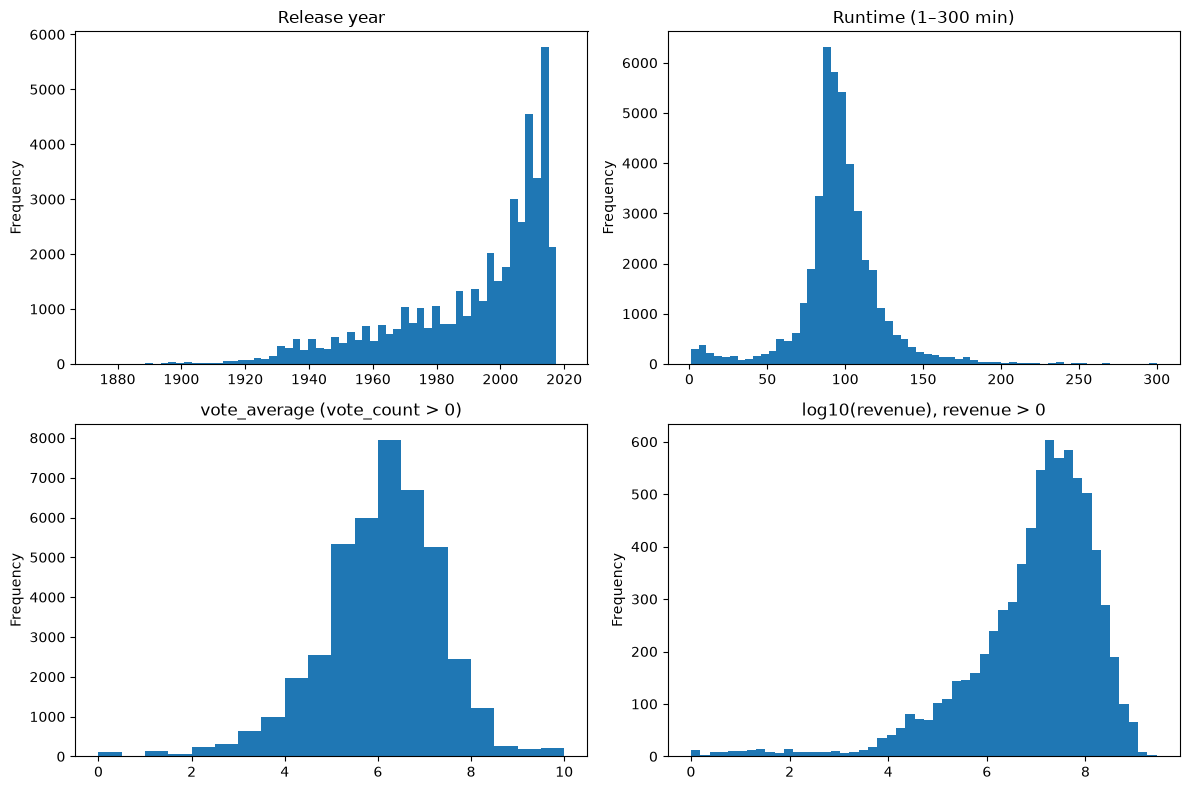

In [9]:
# Histograms of release year, runtime, vote average and log revenue (filtered to remove unknown/extreme values)
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
movies["release_date"].dt.year.plot.hist(bins=60, ax=ax[0, 0], title="Release year")
movies.loc[movies.runtime.between(1, 300), "runtime"].plot.hist(bins=60, ax=ax[0, 1], title="Runtime (1–300 min)")
movies.loc[movies.vote_count > 0, "vote_average"].plot.hist(bins=20, ax=ax[1, 0], title="vote_average (vote_count > 0)")
movies.loc[movies.revenue > 0, "revenue"].apply("log10").plot.hist(bins=50, ax=ax[1, 1], title="log10(revenue), revenue > 0")
plt.tight_layout()

### Outliers
Box plots on a log scale (unknown zeros removed), skewness and the number of IQR outliers (above Q3 + 1.5·IQR) for each skewed column.

,skew,IQR outliers
budget,3.1,930
revenue,5.1,838
runtime,6.7,2181
popularity,29.2,4213
vote_count,10.1,6464


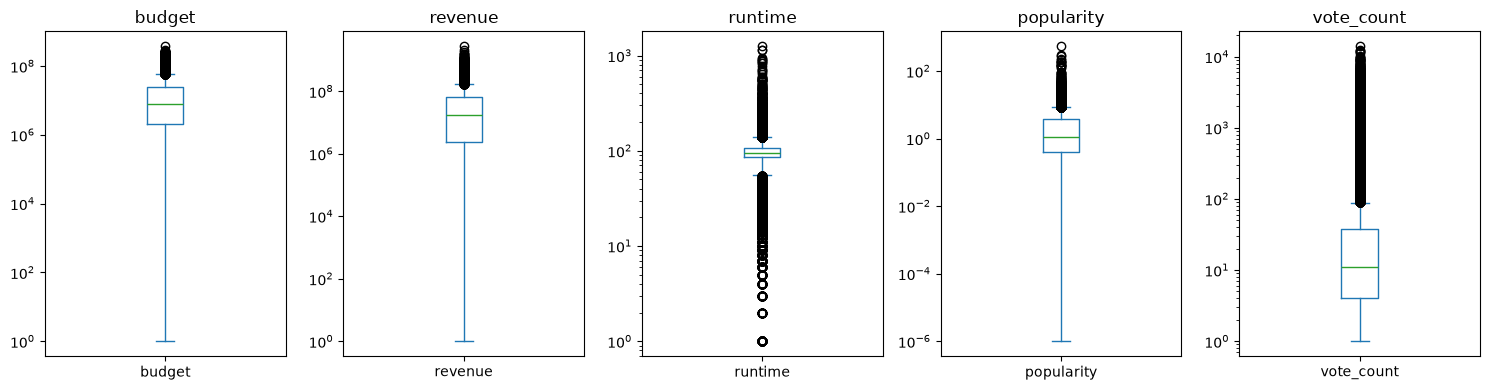

In [10]:
# Box plots of the skewed numeric columns, ignoring zeros (unknown)
skewed = ["budget", "revenue", "runtime", "popularity", "vote_count"]
fig, ax = plt.subplots(1, len(skewed), figsize=(15, 4))
for axis, col in zip(ax, skewed):
    movies.loc[movies[col] > 0, col].plot.box(ax=axis, logy=True, title=col)
plt.tight_layout()

# Count values above Q3 + 1.5 * IQR
def iqr_outliers(values):
    q1, q3 = values.quantile([0.25, 0.75])
    return (values > q3 + 1.5 * (q3 - q1)).sum()

pd.DataFrame({
    "skew": [movies.loc[movies[col] > 0, col].skew() for col in skewed],
    "IQR outliers": [iqr_outliers(movies.loc[movies[col] > 0, col]) for col in skewed],
}, index=skewed).round(1)

In [11]:
# Longest runtimes: check whether they are errors or real (e.g. TV mini-series)
print("Runtime > 300 min:", (movies.runtime > 300).sum())
display(movies.nlargest(5, "runtime")[["title", "runtime", "release_date"]])

# Highest popularity: check whether the extreme values belong to real blockbusters
display(movies.nlargest(5, "popularity")[["title", "popularity", "vote_count", "release_date"]])

# Budgets/revenues below 1000 are not realistic (probably given in millions or placeholders)
tiny = movies.budget.between(1, 999) | movies.revenue.between(1, 999)
print("Budget between 1 and 999:", movies.budget.between(1, 999).sum(), "| revenue between 1 and 999:", movies.revenue.between(1, 999).sum())
display(movies.loc[tiny, ["title", "budget", "revenue"]].head())

# Release dates after the last rating (2017-08-04) are after the dataset was collected
future = movies.release_date > "2017-08-04"
print("Release date after 2017-08-04:", future.sum())
movies.loc[future, "status"].value_counts()

Runtime > 300 min: 108


,title,runtime,release_date
24178,Centennial,1256.0,1978-10-01
19965,Jazz,1140.0,2001-01-09
40938,Baseball,1140.0,1994-09-18
13767,Berlin Alexanderplatz,931.0,1980-08-28
13953,Heimat: A Chronicle of Germany,925.0,1984-09-16


,title,popularity,vote_count,release_date
30700,Minions,547.488298,4729.0,2015-06-17
33356,Wonder Woman,294.337037,5025.0,2017-05-30
42222,Beauty and the Beast,287.253654,5530.0,2017-03-16
43644,Baby Driver,228.032744,2083.0,2017-06-28
24455,Big Hero 6,213.849907,6289.0,2014-10-24


Budget between 1 and 999: 245 | revenue between 1 and 999: 155


,title,budget,revenue
87,Black Sheep,0,32.0
114,Anne Frank Remembered,0,1.0
180,Mute Witness,2,1.0
185,The Prophecy,8,16.0
245,Immortal Beloved,120,0.0


Release date after 2017-08-04: 31


status
Released           17
Post Production    10
In Production       3
Planned             1
Name: count, dtype: int64

### Nested fields

In [12]:
# Parse the nested columns from strings into Python lists/dicts
nested = ["genres", "production_companies", "production_countries", "spoken_languages", "belongs_to_collection"]
for col in nested:
    movies[col] = movies[col].apply(parse)

# Count null vs. empty-list values for each nested column
pd.DataFrame({
    "null": [movies[col].isna().sum() for col in nested],
    "empty": [movies[col].apply(lambda value: isinstance(value, list) and len(value) == 0).sum() for col in nested],
}, index=nested)

,null,empty
genres,0,2442
production_companies,3,11875
production_countries,3,6282
spoken_languages,3,3829
belongs_to_collection,40972,0


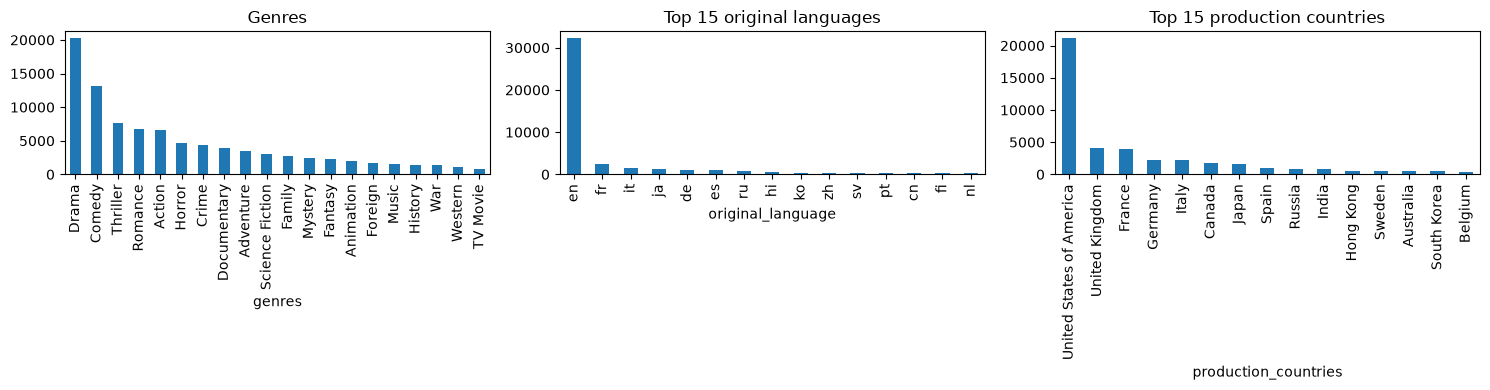

In [13]:
# Bar charts of the most common genres, original languages and production countries
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
movies["genres"].explode().dropna().str["name"].value_counts().plot.bar(ax=ax[0], title="Genres")
movies["original_language"].value_counts().head(15).plot.bar(ax=ax[1], title="Top 15 original languages")
movies["production_countries"].explode().dropna().str["name"].value_counts().head(15).plot.bar(ax=ax[2], title="Top 15 production countries")
plt.tight_layout()

In [14]:
# Number of movies that belong to a collection, and the largest collections
print("Movies in a collection:", movies["belongs_to_collection"].notna().sum())
movies["belongs_to_collection"].dropna().str["name"].value_counts().head(10)

Movies in a collection: 4491


belongs_to_collection
The Bowery Boys                           29
Totò Collection                           27
James Bond Collection                     26
Zatôichi: The Blind Swordsman             26
The Carry On Collection                   25
Pokémon Collection                        22
Charlie Chan (Sidney Toler) Collection    21
Godzilla (Showa) Collection               16
Uuno Turhapuro                            15
Charlie Chan (Warner Oland) Collection    15
Name: count, dtype: int64

### Relationships
How the numeric columns relate to each other, and how genres and runtime change over time.

,budget,revenue,runtime,popularity,vote_average,vote_count
budget,1.00,0.73,0.22,0.37,0.07,0.62
revenue,0.73,1.00,0.20,0.46,0.15,0.78
runtime,0.22,0.20,1.00,0.11,0.11,0.11
popularity,0.37,0.46,0.11,1.00,0.10,0.56
vote_average,0.07,0.15,0.11,0.10,1.00,0.12
vote_count,0.62,0.78,0.11,0.56,0.12,1.00


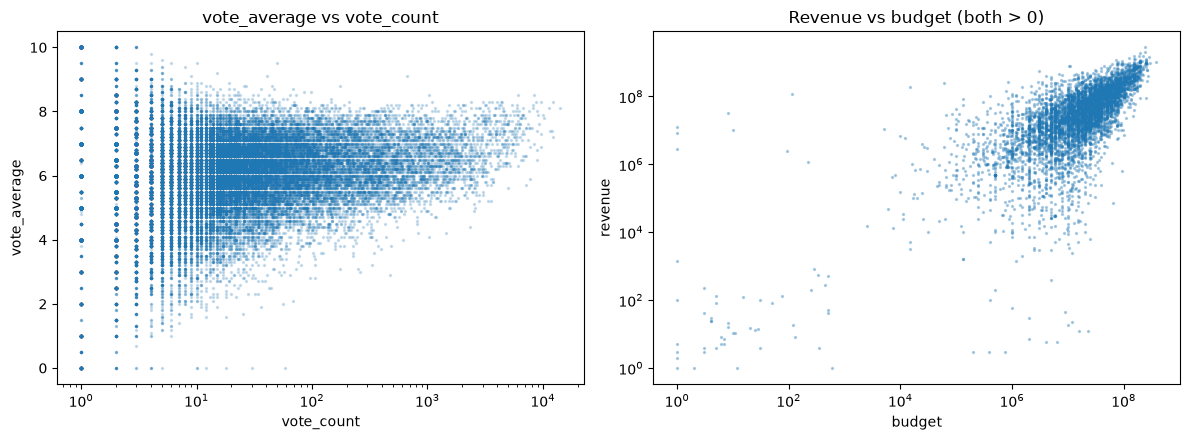

In [15]:
# Scatter plots: vote_average vs vote_count, and revenue vs budget (log scales, unknown zeros removed)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
movies[movies.vote_count > 0].plot.scatter(x="vote_count", y="vote_average", logx=True, s=2, alpha=0.2, ax=ax[0], title="vote_average vs vote_count")
movies[(movies.budget > 0) & (movies.revenue > 0)].plot.scatter(x="budget", y="revenue", loglog=True, s=2, alpha=0.3, ax=ax[1], title="Revenue vs budget (both > 0)")
plt.tight_layout()

# Correlation between the numeric columns, with zeros treated as missing
numeric = ["budget", "revenue", "runtime", "popularity", "vote_average", "vote_count"]
movies[numeric].where(movies[numeric] > 0).corr().round(2)

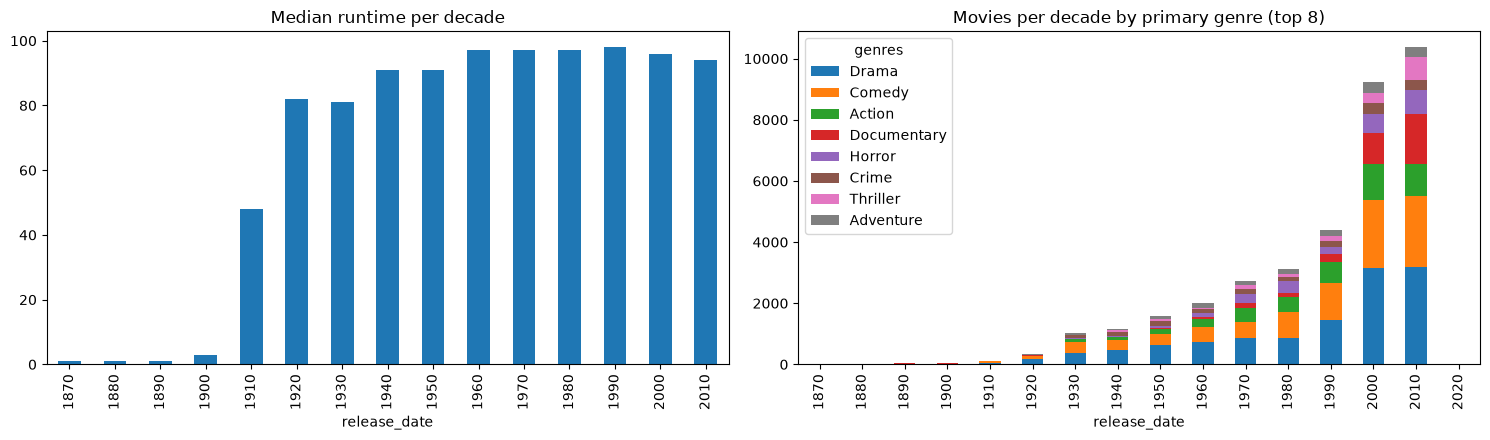

In [16]:
# Decade and primary genre (first element in genres), as used in Part 2 question 5
decade = (movies["release_date"].dt.year // 10 * 10).astype("Int64")
primary_genre = movies["genres"].str[0].str["name"]

# Median runtime per decade (ignoring unknown and extreme runtimes) and movie count per decade and primary genre
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
movies.loc[movies.runtime.between(1, 300), "runtime"].groupby(decade).median().plot.bar(ax=ax[0], title="Median runtime per decade")
top_genres = primary_genre.value_counts().head(8).index
pd.crosstab(decade, primary_genre)[top_genres].plot.bar(stacked=True, ax=ax[1], title="Movies per decade by primary genre (top 8)")
plt.tight_layout()

## credits.csv

In [17]:
# Load credits, check duplicates and parse the cast/crew lists
credits = pd.read_csv(DATA + "credits.csv")
print(credits.shape, "| duplicate ids:", credits["id"].duplicated().sum())
credits["cast"] = credits["cast"].apply(parse)
credits["crew"] = credits["crew"].apply(parse)
# Check empty cast/crew lists, ids missing from movies, and movies without a director
print("Empty cast:", (credits["cast"].str.len() == 0).sum(), "| empty crew:", (credits["crew"].str.len() == 0).sum())
print("Ids not in movies:", (~credits["id"].isin(movies["id"])).sum())
print("Movies without director:", (~credits["crew"].apply(lambda crew_list: any(person["job"] == "Director" for person in crew_list))).sum())

(45476, 3) | duplicate ids: 44


Empty cast: 2418 | empty crew: 771
Ids not in movies: 0
Movies without director: 887


In [18]:
# Flatten cast and crew so each row is one person in one movie
cast = credits["cast"].explode().dropna()
crew = credits["crew"].explode().dropna()
print("Cast entries:", len(cast), "| crew entries:", len(crew))
# Share of each cast gender and the most common crew jobs
print("Cast gender (0 = unknown, 1 = female, 2 = male):")
print(cast.str["gender"].value_counts(normalize=True).round(3))
crew.str["job"].value_counts().head(10)

Cast entries: 562474 | crew entries: 464314
Cast gender (0 = unknown, 1 = female, 2 = male):


cast
2    0.403
0    0.398
1    0.199
Name: proportion, dtype: float64


crew
Director                   49048
Producer                   43555
Writer                     30431
Screenplay                 25163
Editor                     23800
Director of Photography    20659
Executive Producer         18866
Original Music Composer    15790
Casting                    12635
Art Direction              11689
Name: count, dtype: int64

## keywords.csv

In [19]:
# Load and parse keywords, check duplicates/empty lists and show the most common keywords
keywords = pd.read_csv(DATA + "keywords.csv")
keywords["keywords"] = keywords["keywords"].apply(parse)
print(keywords.shape, "| duplicate ids:", keywords["id"].duplicated().sum())
print("Empty keyword lists:", (keywords["keywords"].str.len() == 0).sum())
keywords["keywords"].explode().dropna().str["name"].value_counts().head(10)

(46419, 2) | duplicate ids: 987
Empty keyword lists: 14795


keywords
woman director      3115
independent film    1930
murder              1308
based on novel       835
musical              734
sex                  685
violence             651
nudity               636
biography            629
revenge              626
Name: count, dtype: int64

## ratings.csv and links.csv

In [20]:
# Load ratings (compact dtypes to save memory) and the MovieLens -> TMDB links
ratings = pd.read_csv(DATA + "ratings.csv", dtype={"userId": "int32", "movieId": "int32", "rating": "float32", "timestamp": "int64"})
links = pd.read_csv(DATA + "links.csv")
# Basic stats: size, unique users/movies, missing values, duplicates and time range
print(ratings.shape, "| users:", ratings.userId.nunique(), "| movies:", ratings.movieId.nunique())
print("Missing values:", ratings.isna().sum().sum(), "| duplicate (user, movie):", ratings.duplicated(["userId", "movieId"]).sum())
print("Timestamp range:", pd.to_datetime(ratings.timestamp.min(), unit="s"), "→", pd.to_datetime(ratings.timestamp.max(), unit="s"))
print("links missing tmdbId:", links.tmdbId.isna().sum())

(26024289, 4) | users: 270896 | movies: 45115


Missing values: 0 | duplicate (user, movie): 0
Timestamp range: 1995-01-09 11:46:44 → 2017-08-04 06:57:50
links missing tmdbId: 219


Users with >= 20 ratings: 166444
Ratings per movie: {'count': 45115.0, 'mean': 576.8, 'std': 3037.4, 'min': 1.0, '25%': 2.0, '50%': 8.0, '75%': 69.0, 'max': 91921.0}


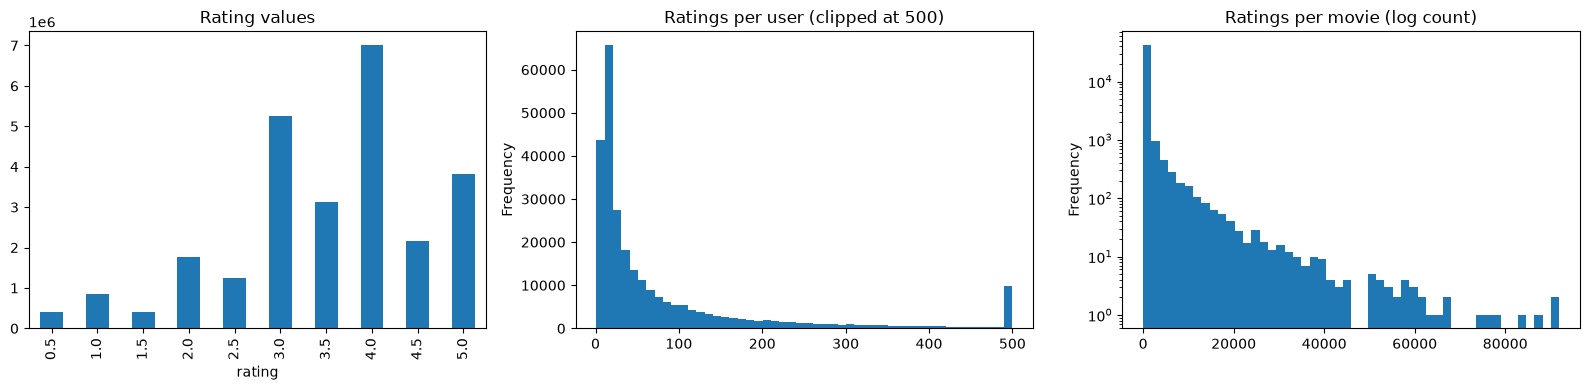

In [21]:
# Distribution of rating values, number of ratings per user and number of ratings per movie
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ratings["rating"].value_counts().sort_index().plot.bar(ax=ax[0], title="Rating values")
ratings.groupby("userId").size().clip(upper=500).plot.hist(bins=50, ax=ax[1], title="Ratings per user (clipped at 500)")
ratings.groupby("movieId").size().plot.hist(bins=50, logy=True, ax=ax[2], title="Ratings per movie (log count)")
plt.tight_layout()
print("Users with >= 20 ratings:", (ratings.groupby("userId").size() >= 20).sum())
print("Ratings per movie:", ratings.groupby("movieId").size().describe().round(1).to_dict())

In [22]:
# Map each rating's MovieLens movieId to a TMDB id and count ratings that cannot be matched to a movie
tmdb = ratings["movieId"].map(links.set_index("movieId")["tmdbId"])
print("Ratings without tmdbId:", tmdb.isna().sum())
print("Ratings whose movie is not in metadata:", (~tmdb.isin(movies["id"])).sum())

Ratings without tmdbId: 13503
Ratings whose movie is not in metadata: 42707


## Findings
- 45,466 movies. 3 malformed rows (shifted columns, non-numeric `id`) are dropped. The row before each of them is cut off (a line break in `overview` split the movie in two), so those 3 rows have no `title`, `popularity` or `vote_count` and should be dropped too.
- There are 30 duplicate ids in metadata: 17 are exact copies and 13 differ only in `popularity`/`vote_count`, so keeping the first row per `id` loses nothing important. Credits (44) and keywords (987) are also deduplicated on `id`.
- `budget` = 0 for 80% and `revenue` = 0 for 84% of movies, so 0 means unknown and is stored as null. Only 5,381 movies have both.
- `belongs_to_collection` (90%), `homepage` (83%) and `tagline` (55%) are mostly missing. `runtime`, `overview` and `release_date` have few gaps.
- 2,899 movies have `vote_count` = 0, so their `vote_average` of 0 is not a real rating. Movies with few votes also have very spread-out averages (the scatter plot narrows as `vote_count` grows), so a `vote_count` threshold is needed when ranking by `vote_average`.
- **Outliers:** all money and count columns are strongly right-skewed (popularity skew ≈ 29). Most extreme values are real: the longest runtimes (up to 1,256 min) are TV mini-series and documentaries, and the most popular movies are recent blockbusters (Minions, Wonder Woman). However, 245 budgets and 155 revenues are between 1 and 999, which is not realistic (probably given in millions). These are kept but should be treated with care in revenue questions. 31 movies have a release date after the last rating (2017-08-04), and 17 of them are still marked "Released".
- **Relationships:** revenue correlates with budget (0.73) and `vote_count` (0.78), but `vote_average` barely correlates with any numeric column (≤ 0.15). The number of movies grows strongly after 1990, and Drama and Comedy dominate as primary genre in every decade. Median runtime stabilises at about 90–100 min from the 1940s; before 1910 almost all movies are shorts.
- Nested fields are Python-literal strings and must be parsed before insertion. Many lists are empty (e.g. 2,442 genres, 11,875 companies).
- 2,418 movies have no cast and 887 have no director. 40% of cast have unknown gender (0), which matters for question 6 in Part 2.
- 26M ratings from 270,896 users, with no missing values or duplicates. Ratings per movie are very long-tailed (median 8, max 91,921). They link to movies via `links.csv` (`movieId` → `tmdbId`). 42,707 ratings cannot be matched to a movie in the metadata; 13,503 of these have no `tmdbId` at all.
- **Limitations:** 0 has to be treated as missing in budget, revenue and runtime, so statistics on these columns only cover a small subset (89% English-language vs. 71% overall). Gender and keyword data are incomplete.